In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
from tqdm import tqdm
import tifffile
from ipywidgets import HBox, VBox

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD Radeon Graphics (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 22.3.6
❗ limited,"llvmpipe (LLVM 15.0.6, 256 bits)",CPU,Vulkan,Mesa 22.3.6 (LLVM 15.0.6)
❌,"AMD Radeon Graphics (gfx1103_r1, LLVM 15.0.6, DRM 3.49, 6.1.0-28-amd64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
from skophys.preprocessing import Vectorizer, UnVectorizer, PercentileFilter

/home/kushal/venvs/fpl/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [4]:
%matplotlib inline

In [5]:
path = "/home/kushal/old-thinkpad-p15v/lab/datasets/jason/M19/D05/M19D5_MC.tif"
movie = tifffile.imread(path)[::10, ::3, ::3]

In [6]:
unvec = UnVectorizer(movie.shape[1:])

In [7]:
def mean_psd(y, method='logmexp'):
    """
    Averaging the PSD

    Args:
        y: np.ndarray
             PSD values

        method: string
            method of averaging the noise.
            Choices:
             'mean': Mean
             'median': Median
             'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        mp: array
            mean psd
    """

    if method == 'mean':
        mp = np.sqrt(np.mean(y / 2, axis=-1))
    elif method == 'median':
        mp = np.sqrt(np.median(y / 2, axis=-1))
    else:
        mp = np.log((y + 1e-10) / 2)
        mp = np.mean(mp, axis=-1)
        mp = np.exp(mp)
        mp = np.sqrt(mp)

    return mp

def get_noise_fft(Y, noise_range=[0.25, 0.5], noise_method='logmexp', max_num_samples_fft=3072,
                  opencv=True):
    """Estimate the noise level for each pixel by averaging the power spectral density.

    Args:
        Y: np.ndarray
            Input movie data with time in the last axis

        noise_range: np.ndarray [2 x 1] between 0 and 0.5
            Range of frequencies compared to Nyquist rate over which the power spectrum is averaged
            default: [0.25,0.5]

        noise method: string
            method of averaging the noise.
            Choices:
                'mean': Mean
                'median': Median
                'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        sn: np.ndarray
            Noise level for each pixel
    """
    T = Y.shape[-1]
    # Y=np.array(Y,dtype=np.float64)

    if T > max_num_samples_fft:
        Y = np.concatenate((Y[..., 1:max_num_samples_fft // 3 + 1],
                            Y[..., int(T // 2 - max_num_samples_fft / 3 / 2)
                                          :int(T // 2 + max_num_samples_fft / 3 / 2)],
                            Y[..., -max_num_samples_fft // 3:]), axis=-1)
        T = np.shape(Y)[-1]

    # we create a map of what is the noise on the FFT space
    ff = np.arange(0, 0.5 + 1. / T, 1. / T)
    ind1 = ff > noise_range[0]
    ind2 = ff <= noise_range[1]
    ind = np.logical_and(ind1, ind2)
    # we compute the mean of the noise spectral density s
    if Y.ndim > 1:
        if opencv:
            import cv2
            try:
                cv2.setNumThreads(0)
            except:
                pass
            psdx_list = []
            for y in Y.reshape(-1, T):
                dft = cv2.dft(y, flags=cv2.DFT_COMPLEX_OUTPUT).squeeze()[
                    :len(ind)][ind]
                psdx_list.append(np.sum(1. / T * dft * dft, 1))
            psdx = np.reshape(psdx_list, Y.shape[:-1] + (-1,))
        else:
            xdft = np.fft.rfft(Y, axis=-1)
            xdft = xdft[..., ind[:xdft.shape[-1]]]
            psdx = 1. / T * abs(xdft)**2
        psdx *= 2
        sn = mean_psd(psdx, method=noise_method)

    else:
        xdft = np.fliplr(np.fft.rfft(Y))
        psdx = 1. / T * (xdft**2)
        psdx[1:] *= 2
        sn = mean_psd(psdx[ind[:psdx.shape[0]]], method=noise_method)

    return sn, psdx

In [8]:
movie = movie.astype(np.float32)

In [9]:
unvec = UnVectorizer(movie.shape[1:])

In [10]:
iw_movie = fpl.ImageWidget(movie, cmap="viridis")
tfig = fpl.Figure()

raw_trace = tfig[0, 0].add_line(np.zeros(movie.shape[0]))

@iw_movie.managed_graphics[0].add_event_handler("click")
def pixel_clicked(ev):
    col, row = ev.pick_info["index"]
    raw_trace.data[:, 1] =  iw_movie.data[0][:, row, col]
    tfig[0, 0].auto_scale(maintain_aspect=False)

HBox([iw_movie.show(), tfig.show()])

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [11]:
iw_movie.window_funcs = {"t": (np.mean, 11)}

In [12]:
filt_movie = PercentileFilter(window_size=10, quantile=10).transform(movie)

In [13]:
iw_movie.set_data(unvec.transform(filt_movie), reset_indices=False)

In [32]:
Y = filt_movie

In [33]:
Y.shape

(29241, 2000)

In [35]:
iw_movie.managed_graphics[0].vmin
max_val = 392

In [36]:
ixs = np.where(Y.max(axis=1) > max_val)[0]

In [37]:
Y = Y[ixs]
unvec.pixel_indices = ixs

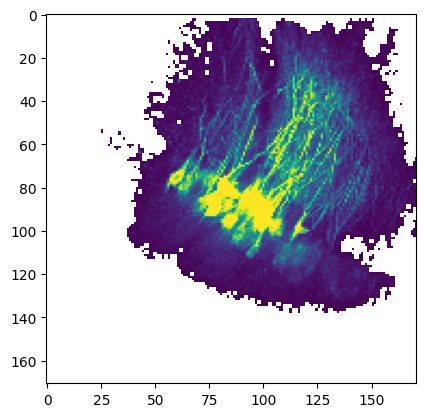

In [38]:
plt.imshow(unvec.transform(Y.max(axis=1)))

In [39]:
((ixs.size ** 2) * 32) / 1024 / 1024 /1024

6.9281759560108185

In [40]:
from numba import guvectorize, float64, int64, float32, prange, njit
from itertools import product

In [41]:
@njit(parallel=True)
def get_distances(
    i: int,
    Y: np.ndarray,
    projections: np.ndarray,
    dists: np.ndarray,
    # low_dists_h: np.ndarray,
    # low_dists_v: np.ndarray,
):
    for j in prange(Y.shape[0]):
        u = Y[i]
        v = Y[j]

        high_val_ixs = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))

        u = u[high_val_ixs]
        v = v[high_val_ixs]

        # u = u**2
        # v = v**2

        # X = np.column_stack([u, v])
        X = np.zeros((u.size, 2))
        X[:, 0] = u
        X[:, 1] = v

        U, S, Vt = np.linalg.svd(X, full_matrices=False)
        v1 = Vt[0, :]

        # projections = (X @ Vt[0, :])[:, None] * Vt[0, :]
        projections_pre = (X @ v1)
        
        projections[j, :u.size, 0] = projections_pre * v1[0]
        projections[j, :u.size, 1] = projections_pre * v1[1]

        orthogonal_distances = np.abs(X - projections[j, :u.size])  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)

        dists[j] = s

        # # hline and vline distances
        # hline = np.array([1., 0.])
        # vline = np.array([0., 1.])

        # projections_h_pre = (X @ hline)
        # projections_v_pre = (X @ vline)

        # projections_h = np.zeros((u.size, 2))
        # projections_h[:, 0] = projections_h_pre * hline[0]
        
        # projections_v = np.zeros((u.size, 2))
        # projections_v[:, 1] = projections_v_pre * vline[1]

        # odists_h = np.abs(X - projections_h)
        # low_dists_h[j] = np.count_nonzero(odists_h < orthogonal_distances) / orthogonal_distances.size

        # odists_v = np.abs(X - projections_v)
        # low_dists_v[j] = np.count_nonzero(odists_v < orthogonal_distances) / orthogonal_distances.size

In [42]:
projections = np.zeros((*Y.shape, 2))
output_matrix = np.zeros((Y.shape[0],))
# output_h = np.zeros((Y.shape[0],))
# output_v = np.zeros((Y.shape[0],))

In [43]:
projections.shape

(15247, 2000, 2)

In [44]:
get_distances(
    17_500,
    Y,
    projections,
    output_matrix,
    # output_h,
    # output_v
)

/tmp/ipykernel_6906/4244620537.py:31: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 2, 'C', False, aligned=True), Array(float64, 1, 'A', False, aligned=True))
  projections_pre = (X @ v1)
/tmp/ipykernel_6906/4244620537.py:31: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 2, 'C', False, aligned=True), Array(float64, 1, 'A', False, aligned=True))
  projections_pre = (X @ v1)


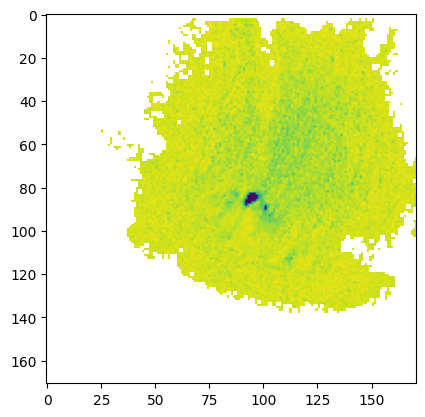

In [45]:
plt.imshow(unvec.transform(output_matrix), cmap="viridis")

In [46]:
from numba import guvectorize, float64, int64, float32, prange, njit

In [47]:
dist_cov = np.zeros((Y.shape[0], Y.shape[0]), dtype=np.float32)

In [48]:
for i in tqdm(range(Y.shape[0])):
    projections = np.zeros((*Y.shape, 2))
    output_matrix = np.zeros((Y.shape[0],))
    # output_h = np.zeros((Y.shape[0],))
    # output_v = np.zeros((Y.shape[0],))
    get_distances(
        i,
        Y,
        projections,
        output_matrix,
        # output_h,
        # output_v,
    )
    dist_cov[i] = output_matrix

100%|██████████████████████████████████████████████████████████████████████| 15247/15247 [16:27<00:00, 15.43it/s]


RFBOutputContext()

JupyterWgpuCanvas(css_height='400px', css_width='700px')
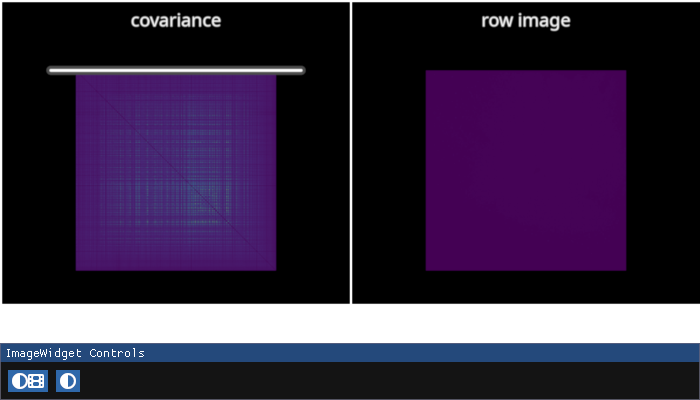

In [57]:
img = unvec.transform(np.nan_to_num(dist_cov, nan=dist_cov.max())[0])

figure_kwargs = {"size": (700, 400), "controller_ids": [[0, 1]]}

iw = fpl.ImageWidget(
    data=[np.nan_to_num(dist_cov, nan=dist_cov.max()), img],
    cmap="viridis",
    names=["covariance", "row image"],
    histogram_widget=False,
    figure_kwargs=figure_kwargs,
)

selector_cov = iw.managed_graphics[0].add_linear_selector(axis="y")

for g in iw.managed_graphics:
    g.vmin, g.vmax = np.nanmin(dist_cov), np.nanmax(dist_cov)

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()

    img = unvec.transform(dist_cov[ix])
    img = np.nan_to_num(img, nan=img.max())

    iw.managed_graphics[1].data = img

iw.show()

In [60]:
selector_cov.get_selected_index()

9345

In [58]:
dist_cov.min(), dist_cov.max()

(np.float32(0.0), np.float32(616179.56))

In [70]:
B = dist_cov.copy()
B -= dist_cov.max()
B = np.abs(B)

# d = 1.0 / np.sum(B.astype(np.float64), axis=0)
# S = np.diag(d) @ B

In [42]:
S.min(), S.max()

(np.float64(0.0), np.float64(0.0006162141185484927))

RFBOutputContext()

JupyterWgpuCanvas(css_height='400px', css_width='700px')
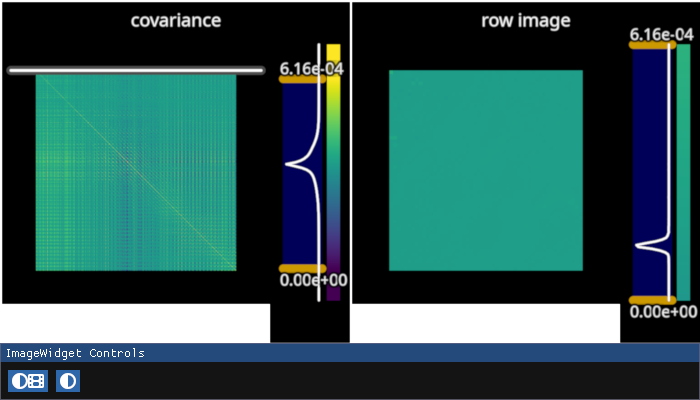

In [45]:
img = unvec.transform(S[0])

figure_kwargs = {"size": (700, 400), "controller_ids": [[0, 1]]}

iw = fpl.ImageWidget(
    data=[S, img],
    cmap="viridis",
    names=["covariance", "row image"],
    figure_kwargs=figure_kwargs,
)

selector_cov = iw.managed_graphics[0].add_linear_selector(axis="y")

for g in iw.managed_graphics:
    g.vmin, g.vmax = S.min(), S.max()

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()

    img = unvec.transform(S[:, ix])

    iw.managed_graphics[1].data = img

iw.show()

In [26]:
selector_cov.get_selected_index()

0

In [27]:
dist_cov.min(), dist_cov.max()

(np.float32(1.549793e-12), np.float32(129912.695))

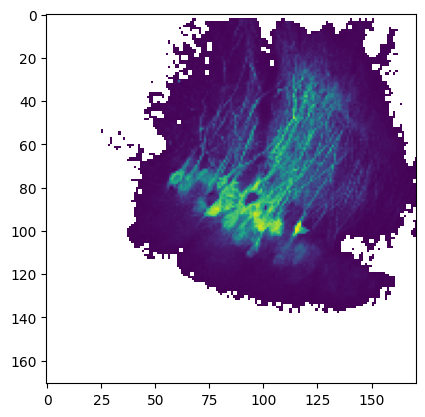

In [88]:
affinity_e = np.exp((-dist_cov**2) / 4e5**2)
plt.imshow(unvec.transform(affinity_e[9345]), cmap="viridis_r")

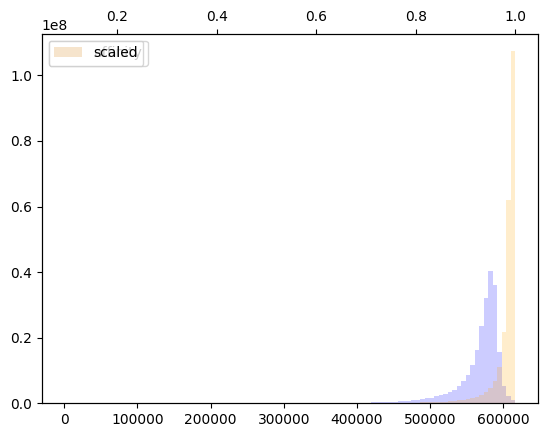

In [90]:
plt.hist(B.ravel(), bins=100, color="b", alpha=0.2, label="affinity")
plt.legend(loc="upper left")
plt.twiny()

# plt.hist(S.ravel(), bins=100, color="g", alpha=0.2, label="stochastic")
# plt.legend(loc="upper center")
# plt.twiny()

plt.hist(affinity_e.ravel(), bins=100, color="orange", alpha=0.2, label="scaled")
plt.legend()

plt.show()

In [89]:
affinity_e.min(), affinity_e.max()

(np.float32(0.09320231), np.float32(1.0))

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas(css_height='400px', css_width='700px')
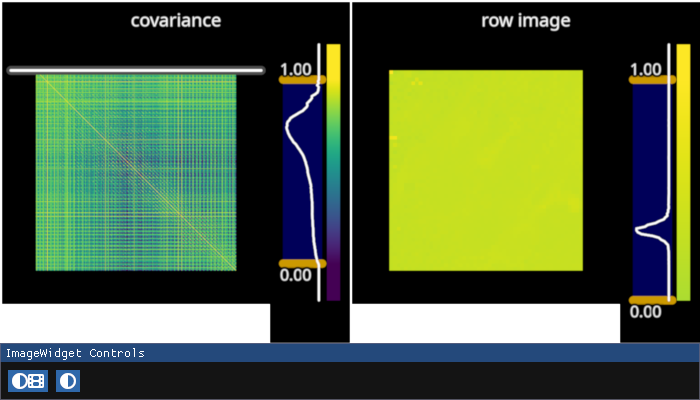

In [152]:
img = unvec.transform(affinity_e[0])

figure_kwargs = {"size": (700, 400), "controller_ids": [[0, 1]]}

iw = fpl.ImageWidget(
    data=[affinity_e, img],
    cmap="viridis",
    names=["covariance", "row image"],
    figure_kwargs=figure_kwargs,
)

selector_cov = iw.managed_graphics[0].add_linear_selector(axis="y")

for g in iw.managed_graphics:
    g.vmin, g.vmax = affinity_e.min(), affinity_e.max()

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()

    img = unvec.transform(affinity_e[ix])

    iw.managed_graphics[1].data = img

iw.show()

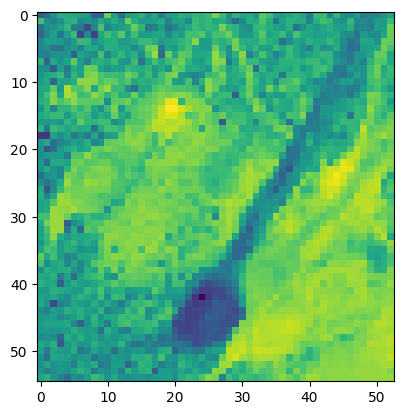

In [153]:
plt.imshow(unvec.transform(dist_cov[2250]))

In [91]:
np.savetxt("./affinity.txt", affinity_e, delimiter=",")

In [92]:
d = "./sym_nmf_results/dendrites_full"
H = np.loadtxt(f"./{d}/H.txt", delimiter=",")
W = np.loadtxt(f"./{d}/W.txt", delimiter=",")

In [93]:
np.linalg.norm(W - H.T)

np.float64(0.0)

In [94]:
iw_symnmf = fpl.ImageWidget([a for a in unvec.transform(W)], histogram_widget=False)
iw_symnmf.show()

RFBOutputContext()

Draw error
Traceback (most recent call last):
  File "/home/kushal/repos/wgpu-py/wgpu/gui/_gui_utils.py", line 76, in log_exception
    yield
  File "/home/kushal/repos/wgpu-py/wgpu/gui/base.py", line 169, in _draw_frame_and_present
    self.draw_frame()
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_imgui_figure.py", line 109, in render
    super().render(draw)
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_figure.py", line 385, in render
    subplot.render()
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_subplot.py", line 155, in render
    super().render()
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_plot_area.py", line 344, in render
    self.viewport.render(self.scene, self.camera)
  File "/home/kushal/repos/pygfx/pygfx/utils/viewport.py", line 78, in render
    self.renderer.render(scene, camera, rect=self.rect, flush=flush)
  File "/home/kushal/repos/pygfx/pygfx/renderers/wgpu/engine/renderer.py", line 531, in render
    comm

JupyterWgpuCanvas()

In [158]:
from scipy.sparse.linalg import eigsh

In [160]:
np.linalg.norm(dist_cov - dist_cov.T, ord="fro")

np.float32(0.0)

In [176]:
evals, evecs = eigsh(dist_cov, k=25, which="LM")

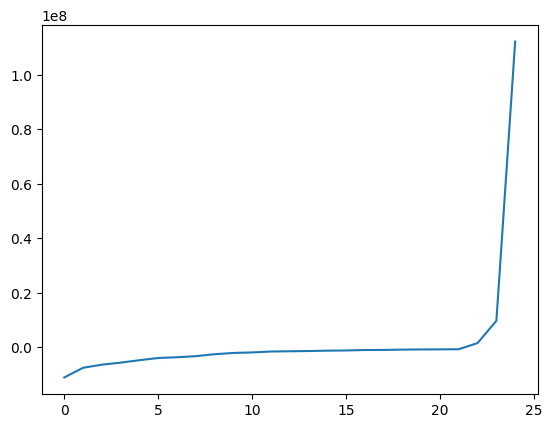

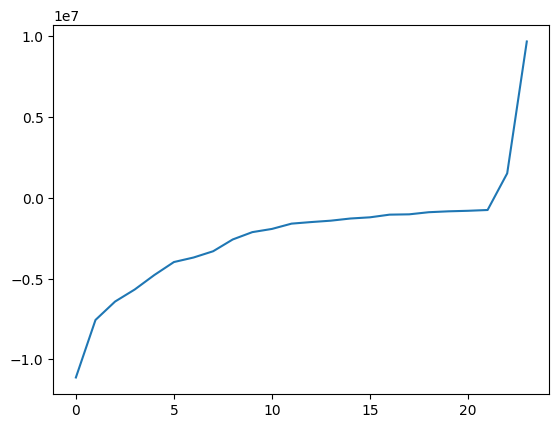

In [177]:
plt.plot(evals)
plt.show()
plt.plot(evals[:-1])

In [183]:
fpl.ImageWidget([a for a in unvec.transform(evecs)], names=[str(i) for i in range(evecs.shape[1])], cmap="viridis").show()

RFBOutputContext()

Draw error
Traceback (most recent call last):
  File "/home/kushal/repos/wgpu-py/wgpu/gui/_gui_utils.py", line 76, in log_exception
    yield
  File "/home/kushal/repos/wgpu-py/wgpu/gui/base.py", line 169, in _draw_frame_and_present
    self.draw_frame()
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_imgui_figure.py", line 109, in render
    super().render(draw)
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_figure.py", line 385, in render
    subplot.render()
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_subplot.py", line 155, in render
    super().render()
  File "/home/kushal/repos/fastplotlib/fastplotlib/layouts/_plot_area.py", line 344, in render
    self.viewport.render(self.scene, self.camera)
  File "/home/kushal/repos/pygfx/pygfx/utils/viewport.py", line 78, in render
    self.renderer.render(scene, camera, rect=self.rect, flush=flush)
  File "/home/kushal/repos/pygfx/pygfx/renderers/wgpu/engine/renderer.py", line 531, in render
    comm

JupyterWgpuCanvas()

In [179]:
evecs.shape

(2915, 25)

In [180]:
evals.shape

(25,)

In [184]:
k = 21

In [185]:
P = evecs[:, :k]
D = np.diag(evals[:k])

In [186]:
A = P @ D @ P.T

In [187]:
A.shape

(2915, 2915)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas(css_height='400px', css_width='700px')
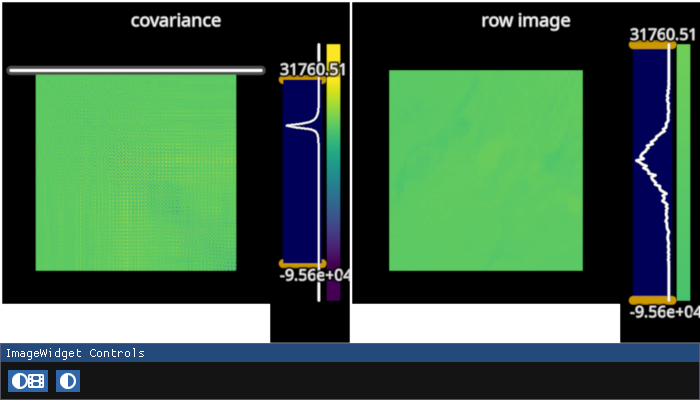

In [206]:
img = unvec.transform(A[0])

figure_kwargs = {"size": (700, 400), "controller_ids": [[0, 1]]}

iw = fpl.ImageWidget(
    data=[A, img],
    cmap="viridis",
    names=["covariance", "row image"],
    figure_kwargs=figure_kwargs,
)

selector_cov = iw.managed_graphics[0].add_linear_selector(axis="y")

for g in iw.managed_graphics:
    g.vmin, g.vmax = A.min(), A.max()

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()

    img = unvec.transform(A[ix])

    iw.managed_graphics[1].data = img

iw.show()

In [208]:
A.min(), A.max()

(np.float32(-95607.34), np.float32(31760.51))

In [189]:
np.savetxt("./affinity.txt", A, delimiter=",")

In [190]:
d = "./sym_nmf_results/dendrites_low_rank"
H = np.loadtxt(f"./{d}/H.txt", delimiter=",")
W = np.loadtxt(f"./{d}/W.txt", delimiter=",")

In [202]:
W.min(), W.max()

(np.float64(0.0), np.float64(0.0))

In [191]:
np.linalg.norm(W - H.T)

np.float64(0.0)

RFBOutputContext()

JupyterWgpuCanvas()
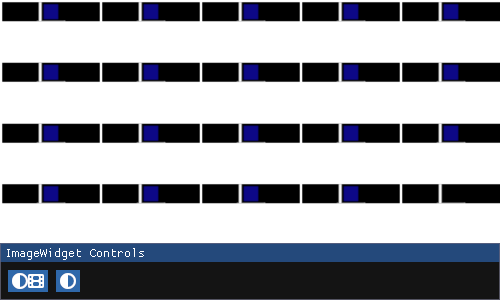

In [192]:
iw_symnmf = fpl.ImageWidget([a for a in unvec.transform(W)], histogram_widget=False)
iw_symnmf.show()